## 0. Session setup (Colab + GitHub workflow)

In [1]:
from google.colab import userdata
import sys, os, subprocess

TOKEN = userdata.get('GITHUB_TOKEN')
USERNAME = "vedika0806"
REPO = "data266-5937"
HW = "hw11"

assert USERNAME != "your-github-username" and "XXXX" not in REPO and HW != "hwXX", \
    "Fill in USERNAME, REPO and HW above before running."

os.system(f"git clone https://{TOKEN}@github.com/{USERNAME}/{REPO}.git /content/{REPO}")

sys.path.append(f"/content/{REPO}/common")
import colab_bootstrap
import importlib
importlib.reload(colab_bootstrap)
from colab_bootstrap import setup_repo, get_logger, git_commit_push, git_tag_push

REPO_PATH = f"/content/{REPO}"
HW_PATH = setup_repo(HW, USERNAME, REPO, TOKEN)
logger = get_logger(HW_PATH)

logger.info(f"=== Session started for {HW} ===")
git_commit_push(REPO_PATH, f"{HW}: session start")

INFO:/content/data266-5937/hw11:=== Session started for hw11 ===


Working directory: /content/data266-5937/hw11
[main 00908ad] hw11: session start
 2 files changed, 1 insertion(+)
 


In [2]:
SID4 = 5937


SEED = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10

print(f"SID4={SID4}, SEED={SEED}, SLICE={SLICE}, HP_ID={HP_ID}, CLS_A={CLS_A}, CLS_B={CLS_B}")
logger.info(f"Params: SID4={SID4}, SEED={SEED}, SLICE={SLICE}, HP_ID={HP_ID}, CLS_A={CLS_A}, CLS_B={CLS_B}")

INFO:/content/data266-5937/hw11:Params: SID4=5937, SEED=5937, SLICE=937, HP_ID=3, CLS_A=7, CLS_B=6


SID4=5937, SEED=5937, SLICE=937, HP_ID=3, CLS_A=7, CLS_B=6


In [3]:
import importlib.util
if importlib.util.find_spec("tabulate") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "tabulate"], check=True)

import random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from torchvision.datasets import CIFAR10
from transformers import CLIPProcessor, CLIPModel
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_auc_score
from tqdm.auto import tqdm

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)
logger.info(f"Imports done, device={device}")

INFO:/content/data266-5937/hw11:Imports done, device=cuda


Device: cuda


In [4]:
MODEL_ID = "openai/clip-vit-base-patch32"
model = CLIPModel.from_pretrained(MODEL_ID).to(device).eval()
processor = CLIPProcessor.from_pretrained(MODEL_ID)

print("Embedding dim:", model.config.projection_dim)
print("Learned logit scale (temperature):", round(model.logit_scale.exp().item(), 2))
logger.info(f"Loaded CLIP model {MODEL_ID}")

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

INFO:/content/data266-5937/hw11:Loaded CLIP model openai/clip-vit-base-patch32


Embedding dim: 512
Learned logit scale (temperature): 100.0


In [5]:
cifar = CIFAR10(root="data", train=False, download=True)     # PIL images, 32x32 RGB
cifar_classes = cifar.classes
cifar_labels = np.array(cifar.targets)

N_PER_CLASS = 100
rng = np.random.default_rng(SEED)
sample_idx = np.concatenate([
    rng.choice(np.where(cifar_labels == c)[0], N_PER_CLASS, replace=False)
    for c in range(len(cifar_classes))
])
sample_labels = cifar_labels[sample_idx]

print("Classes:", cifar_classes)
print("Sampled images:", len(sample_idx), "| per class:", np.bincount(sample_labels).tolist())
logger.info(f"Loaded CIFAR-10 test set, sampled {N_PER_CLASS}/class = {len(sample_idx)} images (seed={SEED})")
git_commit_push(REPO_PATH, f"{HW}: load CLIP + sample CIFAR-10 100/class")

100%|██████████| 170M/170M [20:58<00:00, 135kB/s]
INFO:/content/data266-5937/hw11:Loaded CIFAR-10 test set, sampled 100/class = 1000 images (seed=5937)


Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Sampled images: 1000 | per class: [100, 100, 100, 100, 100, 100, 100, 100, 100, 100]
[main d0f763d] hw11: load CLIP + sample CIFAR-10 100/class
 10 files changed, 5 insertions(+)
 create mode 100644 hw11/data/cifar-10-batches-py/batches.meta
 create mode 100644 hw11/data/cifar-10-batches-py/data_batch_1
 create mode 100644 hw11/data/cifar-10-batches-py/data_batch_2
 create mode 100644 hw11/data/cifar-10-batches-py/data_batch_3
 create mode 100644 hw11/data/cifar-10-batches-py/data_batch_4
 create mode 100644 hw11/data/cifar-10-batches-py/data_batch_5
 create mode 100644 hw11/data/cifar-10-batches-py/readme.html
 create mode 100644 hw11/data/cifar-10-batches-py/test_batch
 create mode 100644 hw11/data/cifar-10-python.tar.gz
 


In [6]:
TEMPLATE = "an image of a {}"
TARGET_CLASS = cifar_classes[CLS_A]
CAPTION = TEMPLATE.format(TARGET_CLASS)
print(f"CLS_A = {CLS_A} -> target class = '{TARGET_CLASS}'")
print(f"Caption: '{CAPTION}'")
logger.info(f"Caption defined: '{CAPTION}' (CLS_A={CLS_A})")

INFO:/content/data266-5937/hw11:Caption defined: 'an image of a horse' (CLS_A=7)


CLS_A = 7 -> target class = 'horse'
Caption: 'an image of a horse'


## 1.4 Preprocess images & extract normalized embeddings
* **Preprocess:** each image is passed to the processor as a PIL image, as in the demo. The processor resizes it from 32×32 to 224×224 and applies CLIP's mean/std normalization.
* **Extract:** the vision and text towers each produce a pooled output, which is projected into the shared 512-d space with `visual_projection` / `text_projection`. These are the same steps `CLIPModel.forward` runs internally.
* **Normalize:** each embedding is divided by its L2 norm, so a dot product equals cosine similarity.

In [7]:
@torch.no_grad()
def encode_texts(texts):
    tok = processor(text=texts, return_tensors="pt", padding=True).to(device)
    out = model.text_model(input_ids=tok["input_ids"], attention_mask=tok["attention_mask"])
    emb = model.text_projection(out.pooler_output)
    return (emb / emb.norm(dim=-1, keepdim=True)).cpu()

@torch.no_grad()
def encode_images(pil_images, batch_size=256, desc="Encoding images"):
    embs = []
    for i in tqdm(range(0, len(pil_images), batch_size), desc=desc):
        px = processor(images=pil_images[i:i + batch_size], return_tensors="pt")["pixel_values"].to(device)
        out = model.vision_model(pixel_values=px)
        emb = model.visual_projection(out.pooler_output)
        embs.append((emb / emb.norm(dim=-1, keepdim=True)).cpu())
    return torch.cat(embs)

sample_pils = [cifar[i][0] for i in sample_idx]              # 32x32 RGB PIL (CLIP inputs + display)

text_emb = encode_texts([CAPTION])                            # (1, 512)
img_emb = encode_images(sample_pils)                          # (1000, 512)

print("Text embedding:", tuple(text_emb.shape), "| Image embeddings:", tuple(img_emb.shape))
print("Norms (should be 1.0):", round(text_emb.norm(dim=-1).item(), 4),
      round(img_emb.norm(dim=-1).min().item(), 4), "-", round(img_emb.norm(dim=-1).max().item(), 4))
logger.info("Extracted + L2-normalized CLIP embeddings for caption and 1000 images")

Encoding images:   0%|          | 0/4 [00:00<?, ?it/s]

INFO:/content/data266-5937/hw11:Extracted + L2-normalized CLIP embeddings for caption and 1000 images


Text embedding: (1, 512) | Image embeddings: (1000, 512)
Norms (should be 1.0): 1.0 1.0 - 1.0


## 1.5 Compute similarity scores
`cosine = img_emb @ text_emb.T`. Multiplying by CLIP's learned `logit_scale` gives exactly `logits_per_image` from the demo. The assertion below checks that the manual pipeline reproduces `model(**inputs)`.

In [8]:
cos_sim = (img_emb @ text_emb.T).squeeze(1)                  # (1000,)  in [-1, 1]
logit_scale = model.logit_scale.exp().item()

# Sanity check: manual pipeline == CLIPModel.forward (the demo's approach)
with torch.no_grad():
    chk = processor(text=[CAPTION], images=sample_pils[:16], return_tensors="pt", padding=True).to(device)
    ref_logits = model(**chk).logits_per_image[:, 0].cpu()
assert torch.allclose(ref_logits, logit_scale * cos_sim[:16], rtol=1e-3, atol=1e-2), "Manual pipeline mismatch!"
print("Sanity check passed: manual cosine x logit_scale == model(**inputs).logits_per_image")

p1 = pd.DataFrame({
    "dataset_idx": sample_idx,
    "label": sample_labels,
    "class": [cifar_classes[l] for l in sample_labels],
    "cosine": cos_sim.numpy(),
})
p1["is_target"] = p1["label"] == CLS_A

per_class = (p1.groupby("class")["cosine"]
               .agg(["mean", "std", "min", "max"])
               .sort_values("mean", ascending=False))
per_class["rank"] = range(1, len(per_class) + 1)
display(per_class.round(4))
logger.info("Computed cosine similarity for all 1000 images; per-class stats table built")
git_commit_push(REPO_PATH, f"{HW}: part1 embeddings + similarity scores")

Sanity check passed: manual cosine x logit_scale == model(**inputs).logits_per_image


,mean,std,min,max,rank
class,,,,,
horse,0.2757,0.0155,0.2019,0.3003,1
deer,0.2496,0.0157,0.1979,0.2854,2
frog,0.2308,0.0130,0.1928,0.2596,3
dog,0.2304,0.0129,0.2066,0.2645,4
cat,0.2294,0.0121,0.1940,0.2722,5
bird,0.2286,0.0154,0.2008,0.2742,6
airplane,0.2157,0.0132,0.1861,0.2495,7
truck,0.2083,0.0093,0.1835,0.2353,8
automobile,0.2038,0.0114,0.1766,0.2369,9


INFO:/content/data266-5937/hw11:Computed cosine similarity for all 1000 images; per-class stats table built


[main 110930d] hw11: part1 embeddings + similarity scores
 1 file changed, 3 insertions(+)
 


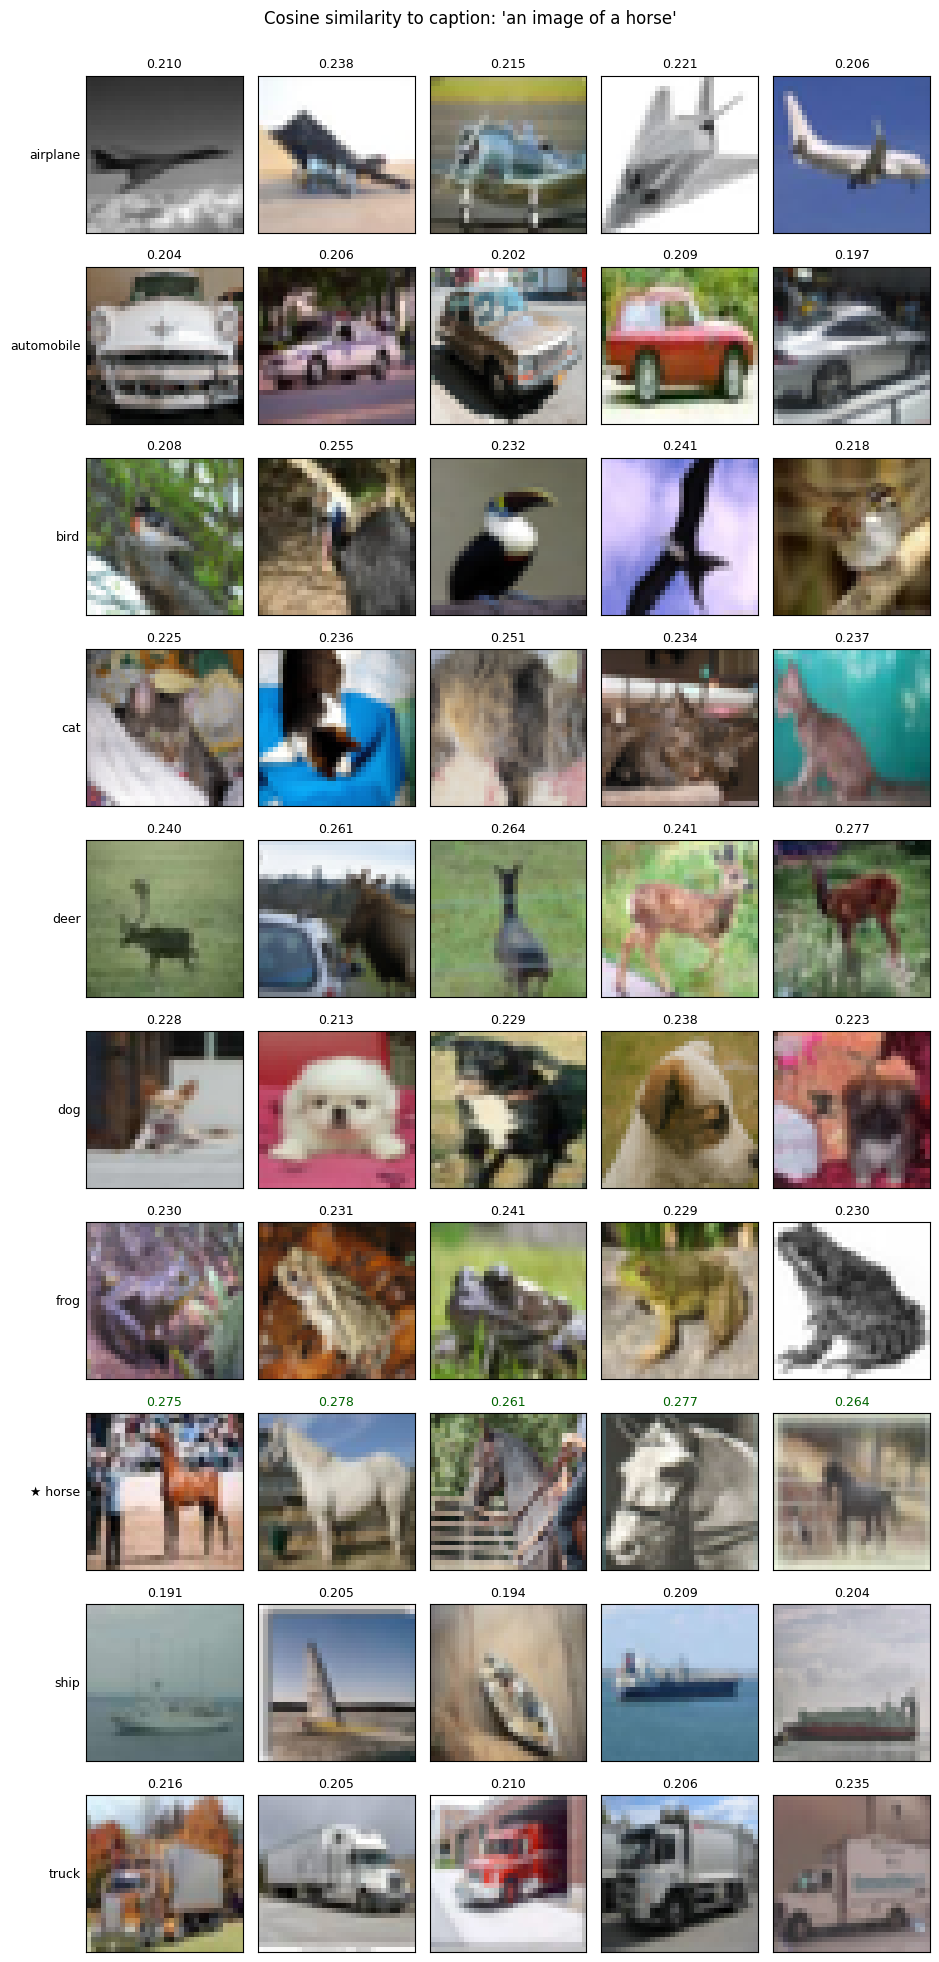

INFO:/content/data266-5937/hw11:Saved p1_images_with_scores_per_class.png


In [9]:
SHOW_PER_CLASS = 5
fig, axes = plt.subplots(len(cifar_classes), SHOW_PER_CLASS, figsize=(SHOW_PER_CLASS * 1.9, len(cifar_classes) * 2.0))
for c, cname in enumerate(cifar_classes):
    rows = p1[p1["label"] == c].sample(SHOW_PER_CLASS, random_state=SEED)
    for j, (pos, r) in enumerate(rows.iterrows()):
        ax = axes[c, j]
        ax.imshow(sample_pils[pos])
        ax.set_title(f"{r.cosine:.3f}", fontsize=9, color="darkgreen" if c == CLS_A else "black")
        ax.set_xticks([]); ax.set_yticks([])
        if j == 0:
            ax.set_ylabel(("★ " if c == CLS_A else "") + cname, fontsize=9, rotation=0, ha="right", va="center")
fig.suptitle(f"Cosine similarity to caption: '{CAPTION}'", fontsize=12)
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.savefig(f"{HW_PATH}/p1_images_with_scores_per_class.png", bbox_inches="tight", dpi=150)
plt.show(); plt.close()
logger.info("Saved p1_images_with_scores_per_class.png")

### (b) The 12 most and 12 least similar images out of all 1,000

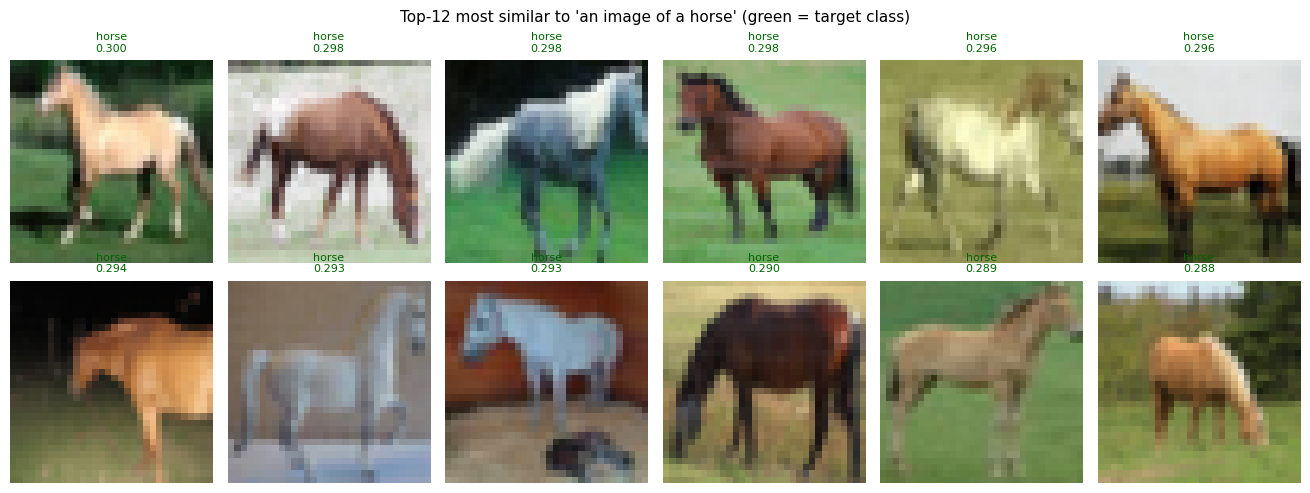

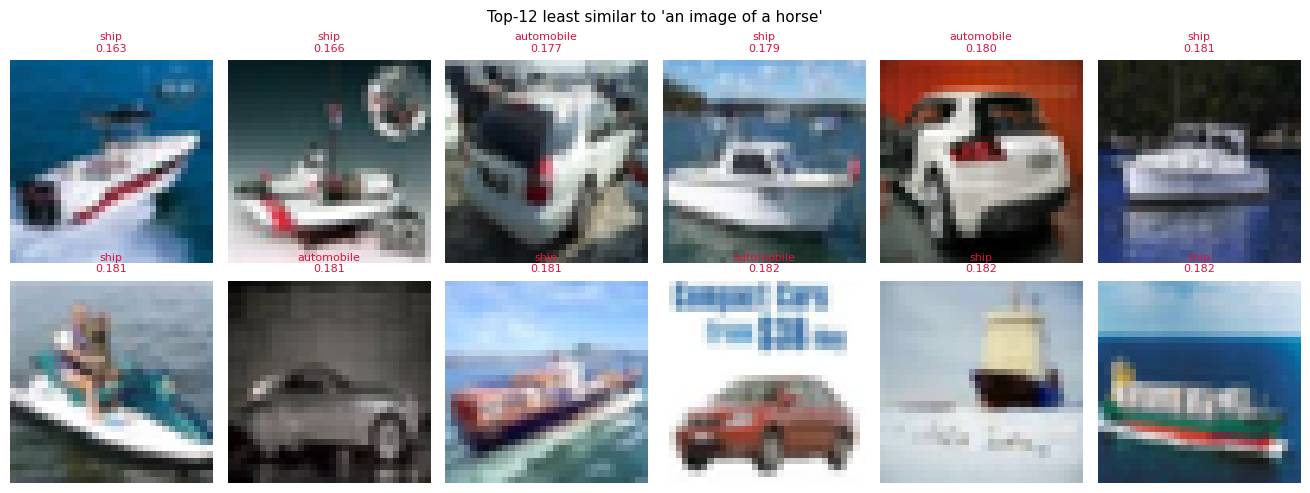

INFO:/content/data266-5937/hw11:Saved p1_top12_most_similar.png and p1_top12_least_similar.png


In [11]:
def show_ranked(df, title, fname, n=12):
    fig, axes = plt.subplots(2, n // 2, figsize=(n * 1.1, 5))
    for ax, (pos, r) in zip(axes.flat, df.head(n).iterrows()):
        ax.imshow(sample_pils[pos])
        ax.set_title(f"{r['class']}\n{r.cosine:.3f}", fontsize=8,
                     color="darkgreen" if r.is_target else "crimson")
        ax.axis("off")
    fig.suptitle(title, fontsize=11)
    plt.tight_layout()
    plt.savefig(f"{HW_PATH}/{fname}", bbox_inches="tight", dpi=150)
    plt.show(); plt.close()

ranked = p1.sort_values("cosine", ascending=False)
show_ranked(ranked, f"Top-12 most similar to '{CAPTION}' (green = target class)", "p1_top12_most_similar.png")
show_ranked(ranked.iloc[::-1], f"Top-12 least similar to '{CAPTION}'", "p1_top12_least_similar.png")
logger.info("Saved p1_top12_most_similar.png and p1_top12_least_similar.png")

### (c) Distribution of similarity scores by class

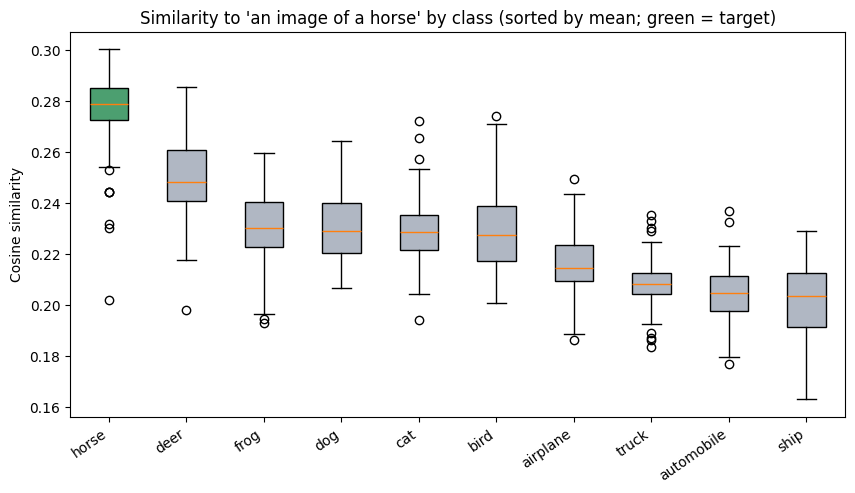

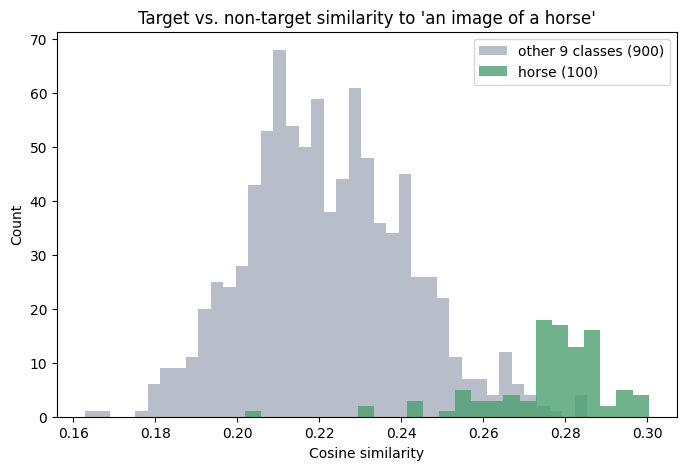

INFO:/content/data266-5937/hw11:Saved p1_similarity_boxplot_by_class.png and p1_similarity_hist_target_vs_rest.png


In [12]:
order = per_class.index.tolist()
plt.figure(figsize=(10, 5))
bp = plt.boxplot([p1.loc[p1["class"] == c, "cosine"] for c in order], patch_artist=True)
plt.xticks(range(1, len(order) + 1), order)
for patch, c in zip(bp["boxes"], order):
    patch.set_facecolor("#4C9F70" if c == TARGET_CLASS else "#B0B7C3")
plt.xticks(rotation=35, ha="right")
plt.ylabel("Cosine similarity")
plt.title(f"Similarity to '{CAPTION}' by class (sorted by mean; green = target)")
plt.savefig(f"{HW_PATH}/p1_similarity_boxplot_by_class.png", bbox_inches="tight", dpi=150)
plt.show(); plt.close()

plt.figure(figsize=(8, 5))
plt.hist(p1.loc[~p1.is_target, "cosine"], bins=40, alpha=0.6, label="other 9 classes (900)", color="#8A94A6")
plt.hist(p1.loc[p1.is_target, "cosine"], bins=25, alpha=0.8, label=f"{TARGET_CLASS} (100)", color="#4C9F70")
plt.xlabel("Cosine similarity"); plt.ylabel("Count"); plt.legend()
plt.title(f"Target vs. non-target similarity to '{CAPTION}'")
plt.savefig(f"{HW_PATH}/p1_similarity_hist_target_vs_rest.png", bbox_inches="tight", dpi=150)
plt.show(); plt.close()
logger.info("Saved p1_similarity_boxplot_by_class.png and p1_similarity_hist_target_vs_rest.png")

### (d) How well does the caption single out its own class?
* **Precision@100:** of the 100 images most similar to the caption, the fraction that belong to the target class (chance = 10%).
* **ROC-AUC:** the probability that a random target image scores higher than a random non-target image (chance = 0.5).

In [13]:
prec_at_100 = ranked.head(100)["is_target"].mean()
auc = roc_auc_score(p1["is_target"], p1["cosine"])
target_rank = int(per_class.loc[TARGET_CLASS, "rank"])
runner_up = [c for c in order if c != TARGET_CLASS][0]
top100_mix = ranked.head(100)["class"].value_counts()

print(f"Target class '{TARGET_CLASS}' mean-similarity rank: {target_rank}/10")
print(f"Precision@100: {prec_at_100:.2%}   (chance = 10%)")
print(f"ROC-AUC (target vs rest): {auc:.4f}   (chance = 0.5)")
print(f"Most similar non-target class: '{runner_up}'")
print("\nClass mix of the 100 most similar images:\n", top100_mix.to_string())

for fname in ["p1_images_with_scores_per_class.png", "p1_top12_most_similar.png", "p1_top12_least_similar.png",
              "p1_similarity_boxplot_by_class.png", "p1_similarity_hist_target_vs_rest.png"]:
    print(f"{fname}: {os.path.getsize(f'{HW_PATH}/{fname}'):,} bytes")
logger.info(f"Part1 metrics: target_rank={target_rank}, P@100={prec_at_100:.4f}, AUC={auc:.4f}")
git_commit_push(REPO_PATH, f"{HW}: part1 figures + retrieval metrics")

INFO:/content/data266-5937/hw11:Part1 metrics: target_rank=1, P@100=0.8100, AUC=0.9723


Target class 'horse' mean-similarity rank: 1/10
Precision@100: 81.00%   (chance = 10%)
ROC-AUC (target vs rest): 0.9723   (chance = 0.5)
Most similar non-target class: 'deer'

Class mix of the 100 most similar images:
 class
horse    81
deer     15
bird      3
cat       1
p1_images_with_scores_per_class.png: 309,947 bytes
p1_top12_most_similar.png: 85,600 bytes
p1_top12_least_similar.png: 82,983 bytes
p1_similarity_boxplot_by_class.png: 68,502 bytes
p1_similarity_hist_target_vs_rest.png: 39,899 bytes
[main 0e38b1c] hw11: part1 figures + retrieval metrics
 6 files changed, 4 insertions(+)
 


In [14]:
def append_metrics_section(header, body):
    path = f"{HW_PATH}/METRICS.md"
    existing = open(path).read() if os.path.exists(path) else ""
    if header in existing:
        print(f"'{header}' already in METRICS.md — skipped (delete it from the file first to rewrite).")
        return False
    with open(path, "a") as f:
        f.write(f"\n{header}\n\n{body}\n")
    print(f"{header}\n\n{body}")
    return True

p1_body = f"""Model: `{MODEL_ID}` | Dataset: CIFAR-10 test set, {N_PER_CLASS} images/class × 10 = {len(p1)} images (seed={SEED})
Caption (CLS_A={CLS_A}): **"{CAPTION}"** | Score = cosine similarity of L2-normalized CLIP embeddings

### Per-class similarity to the caption
{per_class.round(4).to_markdown()}

### Does the caption single out its class?
| Metric | Value | Chance |
|---|---|---|
| Target class rank by mean similarity | {target_rank} / 10 | — |
| Precision@100 | {prec_at_100:.2%} | 10% |
| ROC-AUC (target vs. rest) | {auc:.4f} | 0.5 |
| Most similar non-target class | {runner_up} | — |

Class mix of the 100 most similar images: {", ".join(f"{k}: {v}" for k, v in top100_mix.items())}
"""
if append_metrics_section("## Part 1 — Caption vs. images similarity (CIFAR-10)", p1_body):
    logger.info("Added Part 1 results to METRICS.md")
    git_commit_push(REPO_PATH, f"{HW}: add Part 1 results to METRICS.md")

INFO:/content/data266-5937/hw11:Added Part 1 results to METRICS.md


## Part 1 — Caption vs. images similarity (CIFAR-10)

Model: `openai/clip-vit-base-patch32` | Dataset: CIFAR-10 test set, 100 images/class × 10 = 1000 images (seed=5937)
Caption (CLS_A=7): **"an image of a horse"** | Score = cosine similarity of L2-normalized CLIP embeddings

### Per-class similarity to the caption
| class      |   mean |    std |    min |    max |   rank |
|:-----------|-------:|-------:|-------:|-------:|-------:|
| horse      | 0.2757 | 0.0155 | 0.2019 | 0.3003 |      1 |
| deer       | 0.2496 | 0.0157 | 0.1979 | 0.2854 |      2 |
| frog       | 0.2308 | 0.013  | 0.1928 | 0.2596 |      3 |
| dog        | 0.2304 | 0.0129 | 0.2066 | 0.2645 |      4 |
| cat        | 0.2294 | 0.0121 | 0.194  | 0.2722 |      5 |
| bird       | 0.2286 | 0.0154 | 0.2008 | 0.2742 |      6 |
| airplane   | 0.2157 | 0.0132 | 0.1861 | 0.2495 |      7 |
| truck      | 0.2083 | 0.0093 | 0.1835 | 0.2353 |      8 |
| automobile | 0.2038 | 0.0114 | 0.1766 | 0.2369 |      9 |
| ship       | 0.2018 |

---
# Part 2 — Zero-shot classification on CIFAR-10 (full 10,000-image test set)

Each class name becomes a text prompt with the same demo template (`"an image of a {class}"`). Each image is assigned to the prompt with the highest cosine similarity, which is equivalent to the demo's `logits_per_image.softmax().argmax()`.

In [15]:
# Same CIFAR-10 test set loaded in Part 1 — now using ALL 10,000 images
cifar_pils = [cifar[i][0] for i in range(len(cifar))]
print("Test images:", len(cifar_pils), "| per class:", np.bincount(cifar_labels).tolist())
logger.info(f"Part 2: using full CIFAR-10 test set ({len(cifar_pils)} images)")

INFO:/content/data266-5937/hw11:Part 2: using full CIFAR-10 test set (10000 images)


Test images: 10000 | per class: [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]


In [16]:
cifar_prompts = [TEMPLATE.format(c) for c in cifar_classes]
cifar_text_emb = encode_texts(cifar_prompts)                          # (10, 512)
cifar_img_emb = encode_images(cifar_pils, desc="CIFAR-10 test")      # (10000, 512)

cifar_sims = cifar_img_emb @ cifar_text_emb.T                         # (10000, 10) cosine
cifar_probs = (logit_scale * cifar_sims).softmax(dim=-1)             # demo-style probabilities
cifar_preds = cifar_sims.argmax(dim=-1).numpy()

overall_acc = (cifar_preds == cifar_labels).mean()
print("Prompts:", cifar_prompts)
print(f"Overall zero-shot accuracy: {overall_acc:.2%}")
logger.info(f"Zero-shot CIFAR-10 done: overall accuracy={overall_acc:.4f}")
git_commit_push(REPO_PATH, f"{HW}: part2 zero-shot predictions on CIFAR-10")

CIFAR-10 test:   0%|          | 0/40 [00:00<?, ?it/s]

INFO:/content/data266-5937/hw11:Zero-shot CIFAR-10 done: overall accuracy=0.8906


Prompts: ['an image of a airplane', 'an image of a automobile', 'an image of a bird', 'an image of a cat', 'an image of a deer', 'an image of a dog', 'an image of a frog', 'an image of a horse', 'an image of a ship', 'an image of a truck']
Overall zero-shot accuracy: 89.06%
[main 61f3d0f] hw11: part2 zero-shot predictions on CIFAR-10
 1 file changed, 2 insertions(+)
 


## 2.1 Per-class accuracy

,correct,total,accuracy,most_confused_with
class,,,,
horse,968,1000,96.80%,dog
truck,968,1000,96.80%,automobile
ship,957,1000,95.70%,airplane
automobile,937,1000,93.70%,truck
airplane,895,1000,89.50%,bird
dog,890,1000,89.00%,cat
bird,875,1000,87.50%,horse
cat,870,1000,87.00%,dog
deer,789,1000,78.90%,horse


              precision    recall  f1-score   support

    airplane     0.9471    0.8950    0.9203      1000
  automobile     0.9522    0.9370    0.9446      1000
        bird     0.8373    0.8750    0.8557      1000
         cat     0.7960    0.8700    0.8313      1000
        deer     0.9174    0.7890    0.8484      1000
         dog     0.8326    0.8900    0.8603      1000
        frog     0.9793    0.7570    0.8539      1000
       horse     0.8323    0.9680    0.8951      1000
        ship     0.9429    0.9570    0.9499      1000
       truck     0.9193    0.9680    0.9430      1000

    accuracy                         0.8906     10000
   macro avg     0.8956    0.8906    0.8903     10000
weighted avg     0.8956    0.8906    0.8903     10000



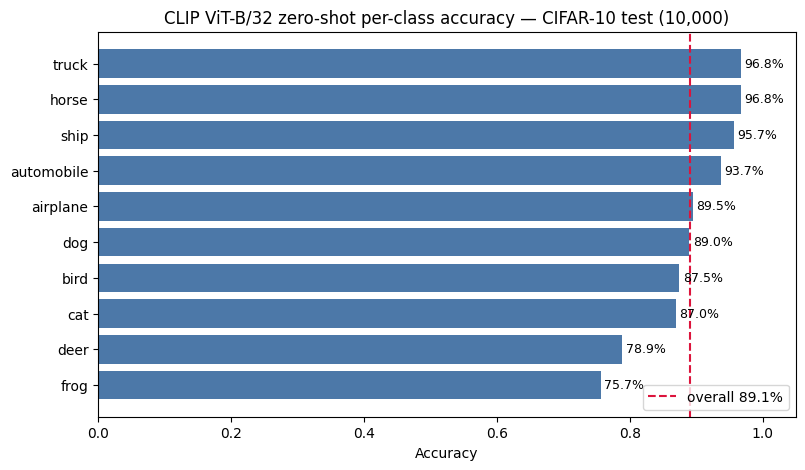

INFO:/content/data266-5937/hw11:Computed per-class accuracy; saved p2_per_class_accuracy.png


In [17]:
cm = confusion_matrix(cifar_labels, cifar_preds, labels=range(len(cifar_classes)))
per_class_acc = pd.DataFrame({
    "class": cifar_classes,
    "correct": np.diag(cm),
    "total": cm.sum(axis=1),
    "accuracy": np.diag(cm) / cm.sum(axis=1),
    "most_confused_with": [cifar_classes[j] for j in np.where(np.eye(len(cifar_classes), dtype=bool), -1, cm).argmax(axis=1)],
}).set_index("class")
display(per_class_acc.sort_values("accuracy", ascending=False).style.format({"accuracy": "{:.2%}"}))
print(classification_report(cifar_labels, cifar_preds, target_names=cifar_classes, digits=4))

plt.figure(figsize=(9, 5))
s = per_class_acc["accuracy"].sort_values()
plt.barh(s.index, s.values, color="#4C78A8")
plt.axvline(overall_acc, color="crimson", ls="--", label=f"overall {overall_acc:.1%}")
for y, v in enumerate(s.values):
    plt.text(v + 0.005, y, f"{v:.1%}", va="center", fontsize=9)
plt.xlim(0, 1.05); plt.xlabel("Accuracy"); plt.legend(loc="lower right")
plt.title("CLIP ViT-B/32 zero-shot per-class accuracy — CIFAR-10 test (10,000)")
plt.savefig(f"{HW_PATH}/p2_per_class_accuracy.png", bbox_inches="tight", dpi=150)
plt.show(); plt.close()
logger.info("Computed per-class accuracy; saved p2_per_class_accuracy.png")

## 2.2 Confusion matrix
Two views: raw counts, and row-normalized percentages (the diagonal equals per-class recall).

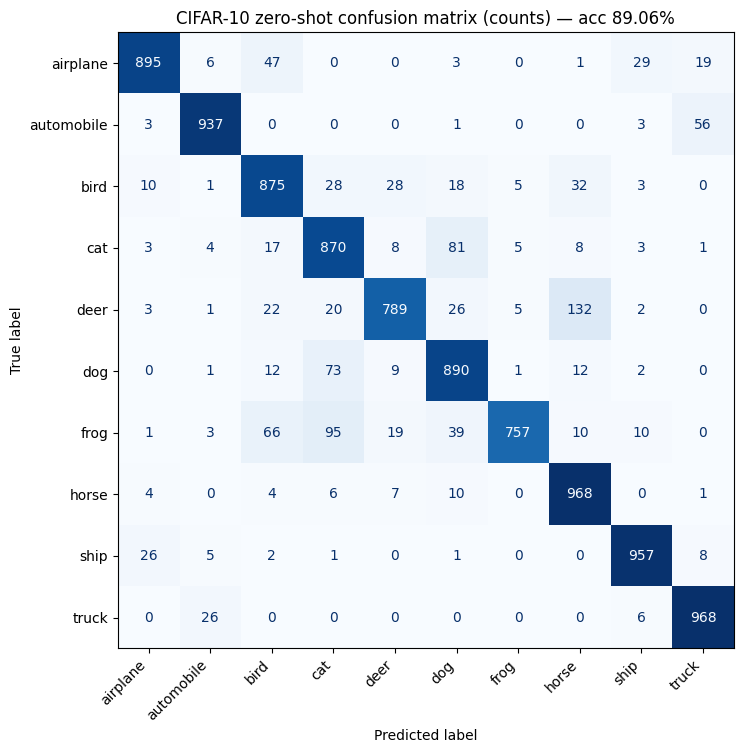

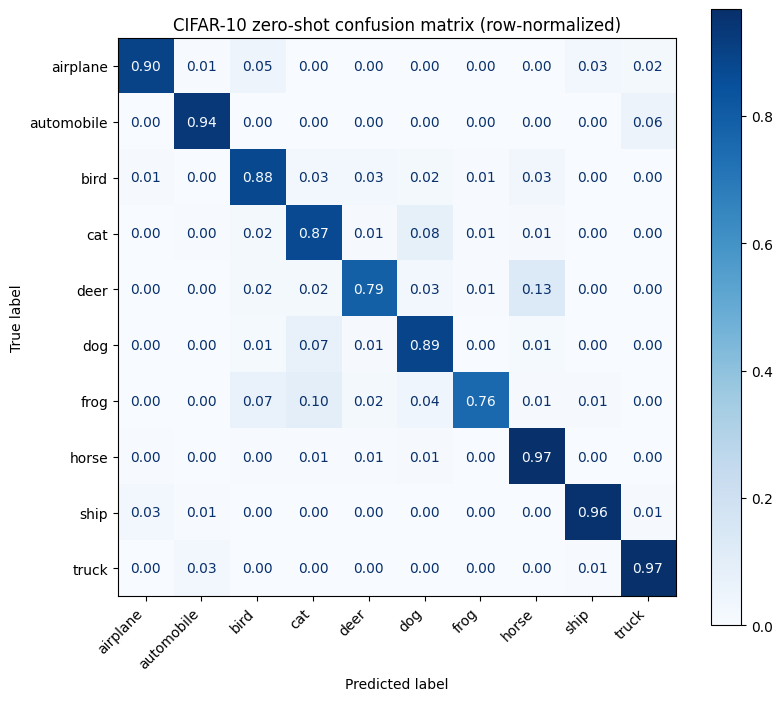

,true,predicted,count
0,deer,horse,132
1,frog,cat,95
2,cat,dog,81
3,dog,cat,73
4,frog,bird,66
5,automobile,truck,56
6,airplane,bird,47
7,frog,dog,39


INFO:/content/data266-5937/hw11:Saved p2_confusion_matrix_counts.png and p2_confusion_matrix_normalized.png


Link to Part 1 — target class 'horse': zero-shot accuracy 96.80%, most confused with 'dog' (Part 1 closest non-target class: 'deer')
[main 6b12a5c] hw11: part2 per-class accuracy + confusion matrix
 4 files changed, 2 insertions(+)
 create mode 100644 hw11/p2_confusion_matrix_counts.png
 create mode 100644 hw11/p2_confusion_matrix_normalized.png
 create mode 100644 hw11/p2_per_class_accuracy.png
 


In [18]:
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm, display_labels=cifar_classes).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
plt.xticks(rotation=45, ha="right")
ax.set_title(f"CIFAR-10 zero-shot confusion matrix (counts) — acc {overall_acc:.2%}")
plt.savefig(f"{HW_PATH}/p2_confusion_matrix_counts.png", bbox_inches="tight", dpi=150)
plt.show(); plt.close()

cm_norm = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm_norm, display_labels=cifar_classes).plot(ax=ax, cmap="Blues", values_format=".2f", colorbar=True)
plt.xticks(rotation=45, ha="right")
ax.set_title("CIFAR-10 zero-shot confusion matrix (row-normalized)")
plt.savefig(f"{HW_PATH}/p2_confusion_matrix_normalized.png", bbox_inches="tight", dpi=150)
plt.show(); plt.close()

off = [(cifar_classes[i], cifar_classes[j], int(cm[i, j]))
       for i in range(len(cifar_classes)) for j in range(len(cifar_classes)) if i != j]
top_confusions = pd.DataFrame(sorted(off, key=lambda t: -t[2])[:8], columns=["true", "predicted", "count"])
display(top_confusions)

print(f"Link to Part 1 — target class '{TARGET_CLASS}': zero-shot accuracy {per_class_acc.loc[TARGET_CLASS, 'accuracy']:.2%}, "
      f"most confused with '{per_class_acc.loc[TARGET_CLASS, 'most_confused_with']}' "
      f"(Part 1 closest non-target class: '{runner_up}')")
logger.info("Saved p2_confusion_matrix_counts.png and p2_confusion_matrix_normalized.png")
git_commit_push(REPO_PATH, f"{HW}: part2 per-class accuracy + confusion matrix")

## 2.3 Example predictions: confident correct and confident wrong

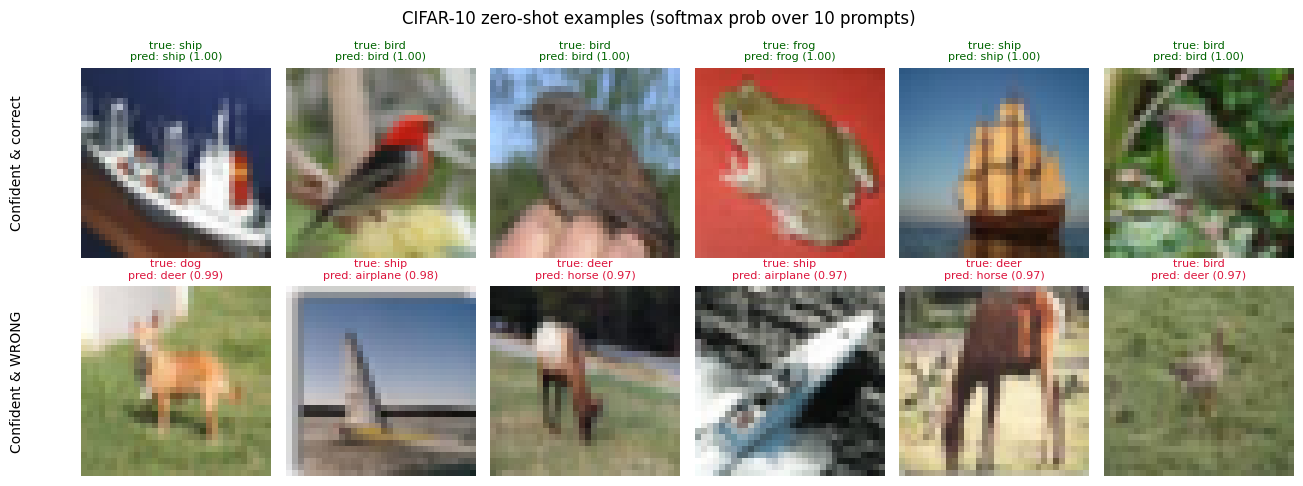

INFO:/content/data266-5937/hw11:Saved p2_example_predictions.png


p2_per_class_accuracy.png: 60,077 bytes
p2_confusion_matrix_counts.png: 105,612 bytes
p2_confusion_matrix_normalized.png: 122,248 bytes
p2_example_predictions.png: 106,920 bytes


In [19]:
conf = cifar_probs.max(dim=-1).values.numpy()
correct_idx = np.where(cifar_preds == cifar_labels)[0]
wrong_idx = np.where(cifar_preds != cifar_labels)[0]
picks = [("Confident & correct", correct_idx[np.argsort(-conf[correct_idx])][:6]),
         ("Confident & WRONG", wrong_idx[np.argsort(-conf[wrong_idx])][:6])]

fig, axes = plt.subplots(2, 6, figsize=(13, 5))
for row, (name, idxs) in enumerate(picks):
    for ax, i in zip(axes[row], idxs):
        ax.imshow(cifar_pils[i])
        ax.set_title(f"true: {cifar_classes[cifar_labels[i]]}\npred: {cifar_classes[cifar_preds[i]]} ({conf[i]:.2f})",
                     fontsize=8, color="darkgreen" if row == 0 else "crimson")
        ax.axis("off")
    axes[row, 0].text(-0.3, 0.5, name, transform=axes[row, 0].transAxes, rotation=90, va="center", ha="right", fontsize=10)
plt.suptitle("CIFAR-10 zero-shot examples (softmax prob over 10 prompts)")
plt.tight_layout()
plt.savefig(f"{HW_PATH}/p2_example_predictions.png", bbox_inches="tight", dpi=150)
plt.show(); plt.close()

for fname in ["p2_per_class_accuracy.png", "p2_confusion_matrix_counts.png",
              "p2_confusion_matrix_normalized.png", "p2_example_predictions.png"]:
    print(f"{fname}: {os.path.getsize(f'{HW_PATH}/{fname}'):,} bytes")
logger.info("Saved p2_example_predictions.png")

## 2.5 Record Part 2 results in METRICS.md

In [22]:
cm_df = pd.DataFrame(cm, index=[f"true: {c}" for c in cifar_classes], columns=cifar_classes)
acc_tbl = per_class_acc.copy(); acc_tbl["accuracy"] = acc_tbl["accuracy"].map("{:.2%}".format)


p2_body = f"""Model: `{MODEL_ID}` | Dataset: CIFAR-10 test set, all {len(cifar_labels):,} images | No training (zero-shot)
Prompts: `{TEMPLATE}` for each class | Prediction = argmax cosine similarity

**Overall accuracy: {overall_acc:.2%}**

### Per-class accuracy
{acc_tbl.to_markdown()}

### Confusion matrix (rows = true, columns = predicted)
{cm_df.to_markdown()}

### Top confusions
{top_confusions.to_markdown(index=False)}

"""
if append_metrics_section("## Part 2 — Zero-shot classification (CIFAR-10)", p2_body):
    logger.info("Added Part 2 results to METRICS.md")
    git_commit_push(REPO_PATH, f"{HW}: add Part 2 results to METRICS.md")

INFO:/content/data266-5937/hw11:Added Part 2 results to METRICS.md


## Part 2 — Zero-shot classification (CIFAR-10)

Model: `openai/clip-vit-base-patch32` | Dataset: CIFAR-10 test set, all 10,000 images | No training (zero-shot)
Prompts: `an image of a {}` for each class | Prediction = argmax cosine similarity

**Overall accuracy: 89.06%**

### Per-class accuracy
| class      |   correct |   total | accuracy   | most_confused_with   |
|:-----------|----------:|--------:|:-----------|:---------------------|
| airplane   |       895 |    1000 | 89.50%     | bird                 |
| automobile |       937 |    1000 | 93.70%     | truck                |
| bird       |       875 |    1000 | 87.50%     | horse                |
| cat        |       870 |    1000 | 87.00%     | dog                  |
| deer       |       789 |    1000 | 78.90%     | horse                |
| dog        |       890 |    1000 | 89.00%     | cat                  |
| frog       |       757 |    1000 | 75.70%     | cat                  |
| horse      |       968 |    1000 | 96.80%  

In [20]:
# Paste your written findings for both parts here, then run to append them to METRICS.md
findings = """
### Part 1 findings: caption "an image of a horse" vs. 100 CIFAR-10 test images per class

- **The caption picks out its class.** Horse has the highest mean cosine similarity (0.2757 ± 0.0155), ahead of deer (0.2496).
  The gap of 0.026 is about 1.7 standard deviations of the horse scores.
  - Precision@100 = 81% (chance = 10%): of the 100 images most similar to the caption, 81 are horses.
  - ROC-AUC = 0.972: a random horse image outscores a random non-horse image about 97% of the time.
- **The ranking follows meaning, not just pixels.** Deer is clearly second, and it supplies 15 of the 19 non-horse images in the top 100
  (the rest: bird 3, cat 1). Deer are the most horse-like class: four-legged, brown, grass and forest backgrounds.
  The other animals (frog, dog, cat, bird) form a middle band (0.229–0.231). All four vehicle classes come last (airplane 0.216, truck 0.208,
  automobile 0.204, ship 0.202). So CLIP's embedding space puts animal images closer to "horse" than vehicle images.
- **Absolute scores are small and tightly packed.** All 1,000 cosine values fall between about 0.16 and 0.30, and the class means differ by at most
  about 0.07. CLIP image–text cosines are usually in this range, so the ranking carries the information, not the raw value.
  The overlap is real: the lowest-scoring horse (0.202) scores below the average airplane, likely a blurry or unusual 32×32 image.
- **Why no softmax:** with a single caption, softmax always returns 1.0, so raw cosine similarity is the only meaningful score here.
  CLIP's learned temperature (logit_scale) only rescales it.

### Part 2 findings: zero-shot classification on all 10,000 CIFAR-10 test images (prompt "an image of a {class}")

- **Overall accuracy is 89.06%** (macro F1 = 0.890) against 10% chance, with no training on CIFAR-10.
  The class names alone, turned into text prompts, act as the classifier.
- **Vehicles are easier than animals.** Truck 96.8%, ship 95.7%, automobile 93.7% and airplane 89.5% average about 94%.
  The six animal classes average about 86%. Horse (96.8%) is the exception among animals.
  The hardest classes are frog (75.7%) and deer (78.9%).
- **The biggest confusions are pairs that look alike or are semantically related:**
  deer→horse (132), frog→cat (95), cat→dog (81), dog→cat (73), frog→bird (66), automobile→truck (56), airplane→bird (47).
  Cat↔dog runs in both directions (81 / 73). Automobile→truck (56) is twice as common as truck→automobile (26).
  Airplane→bird (47) makes sense: a small object against a plain sky looks similar at 32×32.
- **Precision and recall show which classes absorb errors:**
  - Frog has the highest precision (0.979) but the lowest recall (0.757). CLIP rarely says "frog" unless it is sure,
    and its missed frogs spread out to cat, bird and dog.
  - Horse is the opposite (recall 0.968, precision 0.832). It absorbs other animals, especially 132 deer.
  - Cat also absorbs errors (precision 0.796), from frogs and dogs.
- **Confidence is not reliability.** The most confident wrong predictions have softmax probabilities of 0.97–0.99:
  dog→deer, ship→airplane (twice), deer→horse (twice), bird→deer.
  CLIP's large logit scale sharpens the softmax, so a wrong answer can still look almost certain.
- **Low resolution plays a role.** CIFAR images are 32×32 and get upsampled to 224×224 for ViT-B/32. Fine details such as antlers
  or the face shape that separates a cat from a dog are mostly lost, which fits with the worst confusions being between small animals.

### Connecting the two parts
- Part 1's results predict Part 2's. The class closest to "an image of a horse" in Part 1 (deer) is the source of the largest
  confusion in all of Part 2 (132 deer predicted as horse).
- Part 1's high Precision@100 (81%) and AUC (0.97) for horse match horse's high zero-shot recall (96.8%).
- The 15 deer among the top 100 horse-like images in Part 1 explain why horse's precision (0.832) is much lower than its recall.
- The same embedding geometry explains both experiments: deer images sit near the "horse" text embedding.
"""
assert "TODO" not in findings, "Write your findings (replace both TODOs) before running this cell."
if append_metrics_section("## Findings", findings.strip()):
    logger.info("Added written findings to METRICS.md")
    git_commit_push(REPO_PATH, f"{HW}: add written findings to METRICS.md")

INFO:/content/data266-5937/hw11:Added written findings to METRICS.md


## Findings

### Part 1 findings: caption "an image of a horse" vs. 100 CIFAR-10 test images per class

- **The caption picks out its class.** Horse has the highest mean cosine similarity (0.2757 ± 0.0155), ahead of deer (0.2496).
  The gap of 0.026 is about 1.7 standard deviations of the horse scores.
  - Precision@100 = 81% (chance = 10%): of the 100 images most similar to the caption, 81 are horses.
  - ROC-AUC = 0.972: a random horse image outscores a random non-horse image about 97% of the time.
- **The ranking follows meaning, not just pixels.** Deer is clearly second, and it supplies 15 of the 19 non-horse images in the top 100
  (the rest: bird 3, cat 1). Deer are the most horse-like class: four-legged, brown, grass and forest backgrounds.
  The other animals (frog, dog, cat, bird) form a middle band (0.229–0.231). All four vehicle classes come last (airplane 0.216, truck 0.208,
  automobile 0.204, ship 0.202). So CLIP's embedding space puts animal images closer to "horse" than

In [24]:
ai_use_content = """ # AI_USE.md

## 1. What I used AI for vs. wrote myself
- I wrote the CLIP similarity zeroshot code and took help for the zero shot classification part.

## 2. One specific wrong thing the AI produced (pasted)
- AI was not wrong in any outputs specifically.

## 3. How I found out it was wrong
-Answered above

## 4. What I changed and why the fix works
-Answered above
"""
assert "TODO" not in ai_use_content, "Fill in every TODO in AI_USE.md with your own specific answers."
with open(f"{HW_PATH}/AI_USE.md", "w") as f:
    f.write(ai_use_content)
logger.info("Created AI_USE.md")
git_commit_push(REPO_PATH, f"{HW}: add AI_USE.md")

INFO:/content/data266-5937/hw11:Created AI_USE.md


[main a4e6127] hw11: add AI_USE.md
 2 files changed, 14 insertions(+)
 create mode 100644 hw11/AI_USE.md
 


In [27]:
!ls -la {HW_PATH}
!cat {HW_PATH}/METRICS.md
!cat {HW_PATH}/RUN_LOG.txt
!cd {REPO_PATH} && git log --oneline -10
!cd {REPO_PATH} && git status

total 1000
drwxr-xr-x  2 root root   4096 Nov 16 22:32 .
drwxr-xr-x 17 root root   4096 Nov 16 22:23 ..
-rw-r--r--  1 root root    370 Nov 16 22:32 AI_USE.md
-rw-r--r--  1 root root   8624 Nov 16 22:29 METRICS.md
-rw-r--r--  1 root root 309947 Nov 16 21:59 p1_images_with_scores_per_class.png
-rw-r--r--  1 root root  68502 Nov 16 22:00 p1_similarity_boxplot_by_class.png
-rw-r--r--  1 root root  39899 Nov 16 22:00 p1_similarity_hist_target_vs_rest.png
-rw-r--r--  1 root root  82983 Nov 16 22:00 p1_top12_least_similar.png
-rw-r--r--  1 root root  85600 Nov 16 22:00 p1_top12_most_similar.png
-rw-r--r--  1 root root 105612 Nov 16 22:05 p2_confusion_matrix_counts.png
-rw-r--r--  1 root root 122248 Nov 16 22:05 p2_confusion_matrix_normalized.png
-rw-r--r--  1 root root 106920 Nov 16 22:06 p2_example_predictions.png
-rw-r--r--  1 root root  60077 Nov 16 22:05 p2_per_class_accuracy.png
-rw-r--r--  1 root root   2622 Nov 16 22:32 RUN_LOG.txt

## Part 1 — Caption vs. images similarity (CIFAR-10)
